# AI Game Generator: Analisis Data, Modeling, dan GenAI
**Capstone Project Data Science & Generative AI (Celerates)**

**Masalah.** Acara kumpul (kajian, kelas, arisan, sosialisasi desa) sering berakhir dengan semua orang sibuk
main HP sendiri-sendiri. Game party yang ada kaku: pilihannya itu-itu saja (mis. hanya satu jenis game),
harus gonta-ganti aplikasi, dan tidak bisa menyesuaikan materi acara.

**Solusi.** Aplikasi yang (1) membaca tren game dari Google Trends, TikTok, X, dan permintaan di aplikasi,
(2) memprediksi game yang paling diminati dengan model machine learning untuk menjaga library Top-10 + 1 slot
"multiverse" eksperimen, dan (3) memakai agent Generative AI untuk membuat game dari dokumen/topik acara
dan langsung memberi link room host + peserta.

Notebook ini berisi: pemahaman data, preprocessing, EDA, eksperimen 5 model + baseline,
simulasi ground truth Top-10, dan demo komponen GenAI.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .3})
from core.catalog import GAMES, GAME_BY_ID
from core.features import load_raw, clean_requests, build_panel, FEATURES, TARGET
NAMES = {g['id']: g['name'] for g in GAMES}

## 1. Pemahaman Data
Data bersifat **sintetis** (diperbolehkan ketentuan capstone) dan dibuat oleh `scripts/generate_synthetic.py`
dengan proses generatif yang eksplisit:
- `signals_weekly.csv`: sinyal tren mingguan per keyword game, yaitu indeks **Google Trends** (0-100),
  jumlah mention **TikTok** dan **X**. Sinyal sosial dibuat mendahului pencarian ~1 minggu, seperti pola
  viral di dunia nyata. Google Trends asli bisa diambil dengan `scripts/fetch_trends.py` (pytrends).
- `requests_log.csv`: log permintaan room game (1 baris = 1 room), lengkap dengan parameter acara.

In [2]:
reqs, sig = load_raw()
print('requests_log :', reqs.shape); print('signals_weekly:', sig.shape)
reqs.head()

requests_log : (40879, 11)
signals_weekly: (1560, 6)


,request_id,timestamp,game_id,players,duration_min,event_type,mode,location,topic,doc_type,rating
0,R022035,2024-12-02T00:24:00,survival_kuis,13,10,komunitas,offline,Kalimantan Timur,keuangan,topic,2.0
1,R000030,2024-12-02T01:23:00,kuis_kilat,12,20,keluarga,offline,DI Yogyakarta,sejarah,md,3.0
2,R009562,2024-12-02T01:52:00,satu_frekuensi,21,15,kantor,offline,Nusa Tenggara Barat,budaya,pdf,5.0
3,R035514,2024-12-02T01:55:00,harga_pas,5,10,sosialisasi desa,offline,Sulawesi Selatan,umum,pdf,3.0
4,R006408,2024-12-02T02:37:00,fakta_hoaks,12,10,keluarga,offline,Sulawesi Selatan,lingkungan,topic,4.0


In [3]:
info = pd.DataFrame({'dtype': reqs.dtypes.astype(str), 'missing': reqs.isna().sum(),
                     'missing_%': (reqs.isna().mean()*100).round(2), 'unique': reqs.nunique()})
info

,dtype,missing,missing_%,unique
request_id,str,0,0.00,40275
timestamp,str,0,0.00,39459
game_id,str,0,0.00,15
players,int64,0,0.00,30
duration_min,int64,0,0.00,6
event_type,str,0,0.00,7
mode,str,0,0.00,3
location,str,0,0.00,12
topic,str,0,0.00,9
doc_type,str,0,0.00,5


In [4]:
print('Duplikat request_id :', reqs.duplicated('request_id').sum())
print('Pemain tidak valid  :', (reqs['players'] <= 0).sum())
reqs.describe(include='all').T[['count','unique','top','mean','min','max']]

Duplikat request_id : 604
Pemain tidak valid  : 201


,count,unique,top,mean,min,max
request_id,40879,40275,R031807,NaN,NaN,NaN
timestamp,40879,39459,2025-03-14T02:05:00,NaN,NaN,NaN
game_id,40879,15,kuis_kilat,NaN,NaN,NaN
players,40879.0,NaN,NaN,11.71056,0.0,30.0
duration_min,40879.0,NaN,NaN,25.037061,10.0,60.0
event_type,40879,7,keluarga,NaN,NaN,NaN
mode,40879,3,offline,NaN,NaN,NaN
location,40879,12,Jawa Barat,NaN,NaN,NaN
topic,40879,9,agama,NaN,NaN,NaN
doc_type,40879,5,pdf,NaN,NaN,NaN


In [5]:
sig.describe().T

,count,mean,std,min,25%,50%,75%,max
tiktok_mentions,1560.0,138.702564,94.864253,0.0,82.0,128.0,177.0,731.0
x_mentions,1560.0,52.223077,36.982290,0.0,30.0,48.0,67.0,327.0
google_trends,1560.0,46.833974,23.476245,0.0,33.0,45.0,61.0,100.0


**Kamus data `requests_log`:** `game_id` (game yang diminta), `players` (jumlah peserta), `duration_min`,
`event_type` (kajian, kelas/sekolah, kantor, keluarga, komunitas, sosialisasi desa, seminar), `mode`
(offline/online/hybrid), `location` (provinsi), `topic`, `doc_type` (pdf, docx, txt, md, topic), `rating` 1-5.

## 2. Preprocessing

In [6]:
clean = clean_requests(reqs)
print(f'{len(reqs):,} -> {len(clean):,} baris (hapus duplikat & players tidak valid)')
# rating kosong (~8%) tidak dibuang: hanya dipakai untuk analisis kepuasan, diisi median per game
clean['rating_filled'] = clean['rating'].fillna(clean.groupby('game_id')['rating'].transform('median'))
print('rating kosong setelah imputasi:', clean['rating_filled'].isna().sum())

40,879 -> 40,275 baris (hapus duplikat & players tidak valid)
rating kosong setelah imputasi: 0


## 3. Exploratory Data Analysis

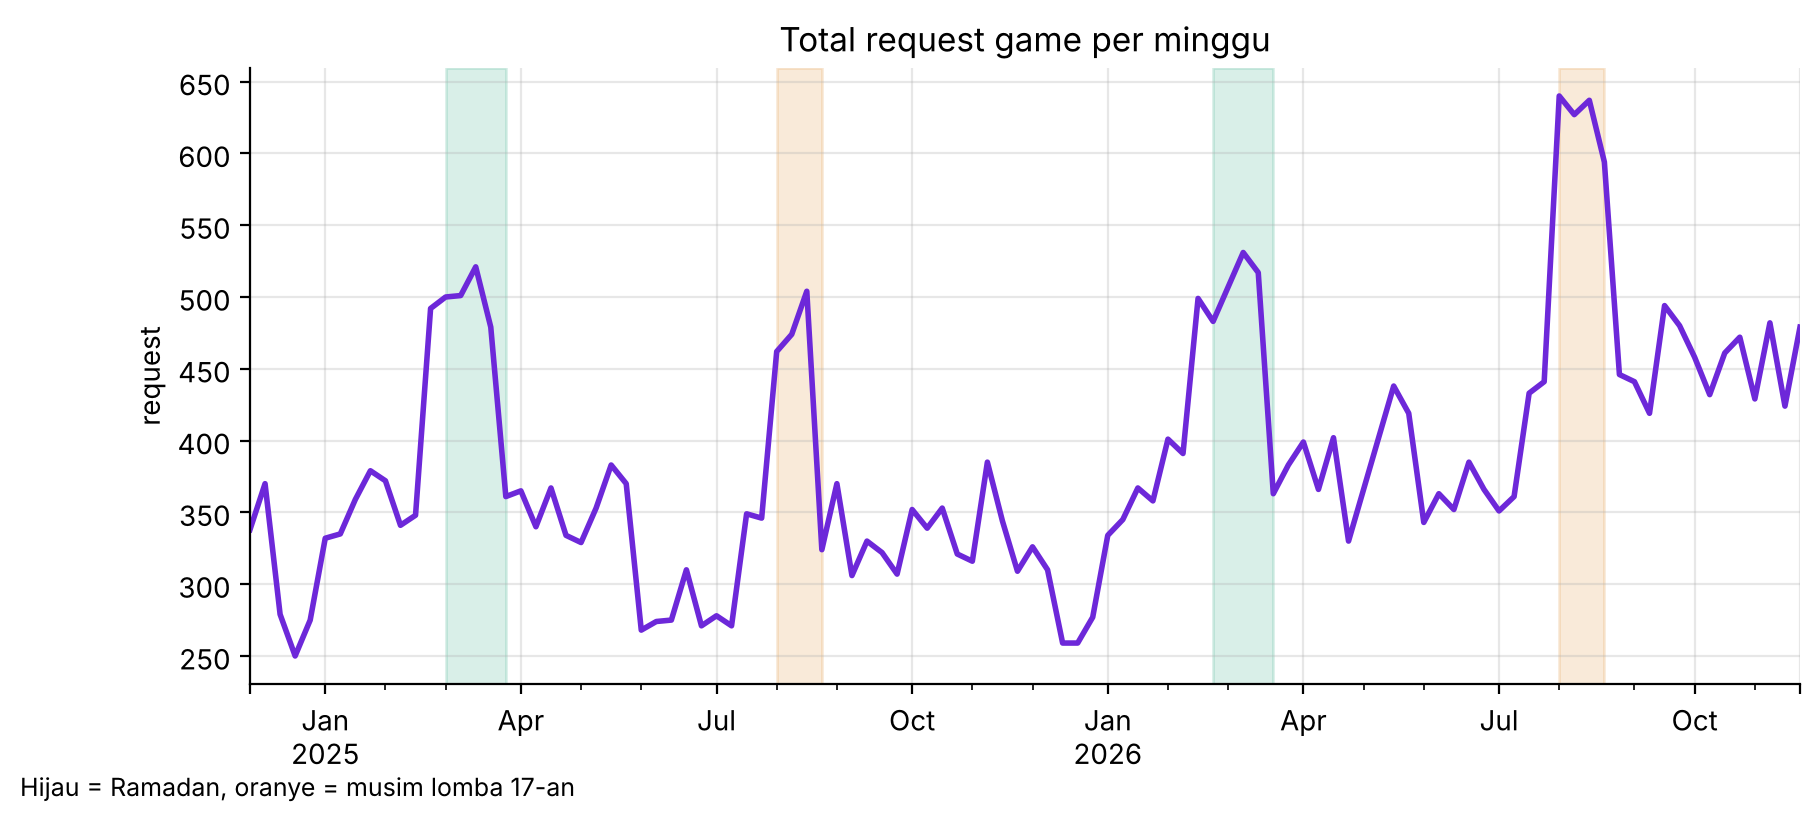

In [7]:
wk = clean.groupby('week').size()
ax = wk.plot(color='#6D28D9', lw=2, title='Total request game per minggu')
for a, b in [('2025-03-01','2025-03-30'), ('2026-02-18','2026-03-19')]:
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color='#059669', alpha=.15)
for y in (2025, 2026):
    ax.axvspan(pd.Timestamp(f'{y}-08-01'), pd.Timestamp(f'{y}-08-24'), color='#D97706', alpha=.15)
ax.set_ylabel('request'); ax.set_xlabel('');
plt.figtext(.01, -.03, 'Hijau = Ramadan, oranye = musim lomba 17-an', fontsize=9); plt.show()

**Insight:** permintaan naik saat Ramadan (banyak kajian/pesantren kilat) dan Agustus (lomba 17-an), turun saat libur akhir tahun dan libur sekolah.

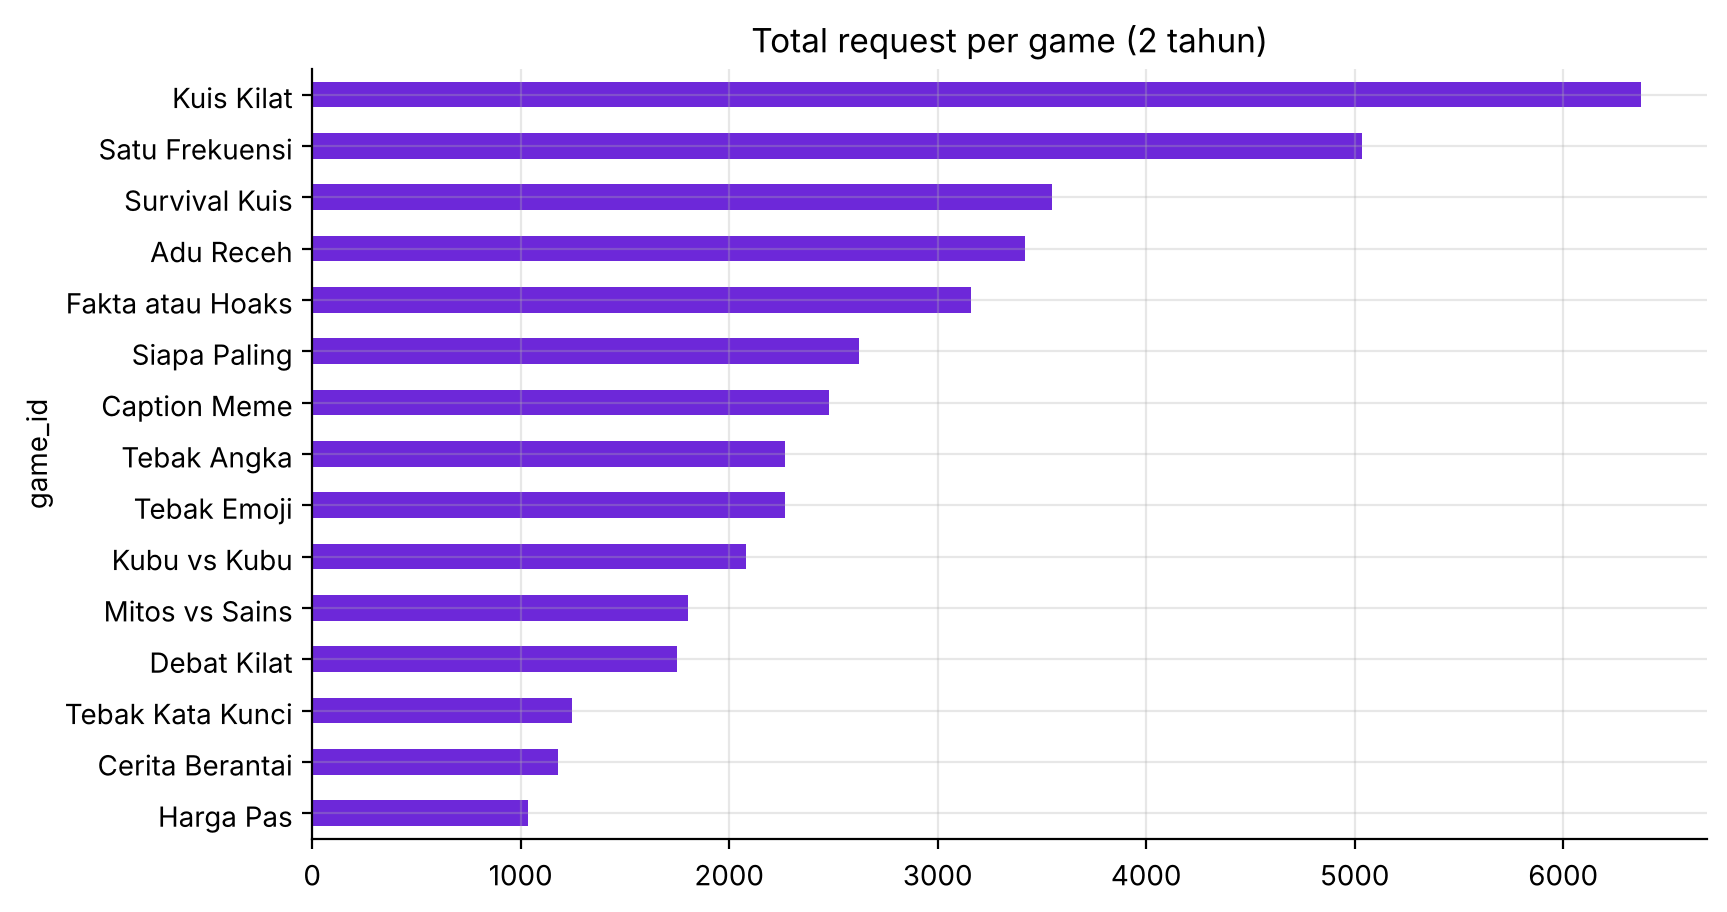

In [8]:
top = clean['game_id'].value_counts().rename(NAMES)
top.sort_values().plot.barh(color='#6D28D9', title='Total request per game (2 tahun)', figsize=(9, 5)); plt.show()

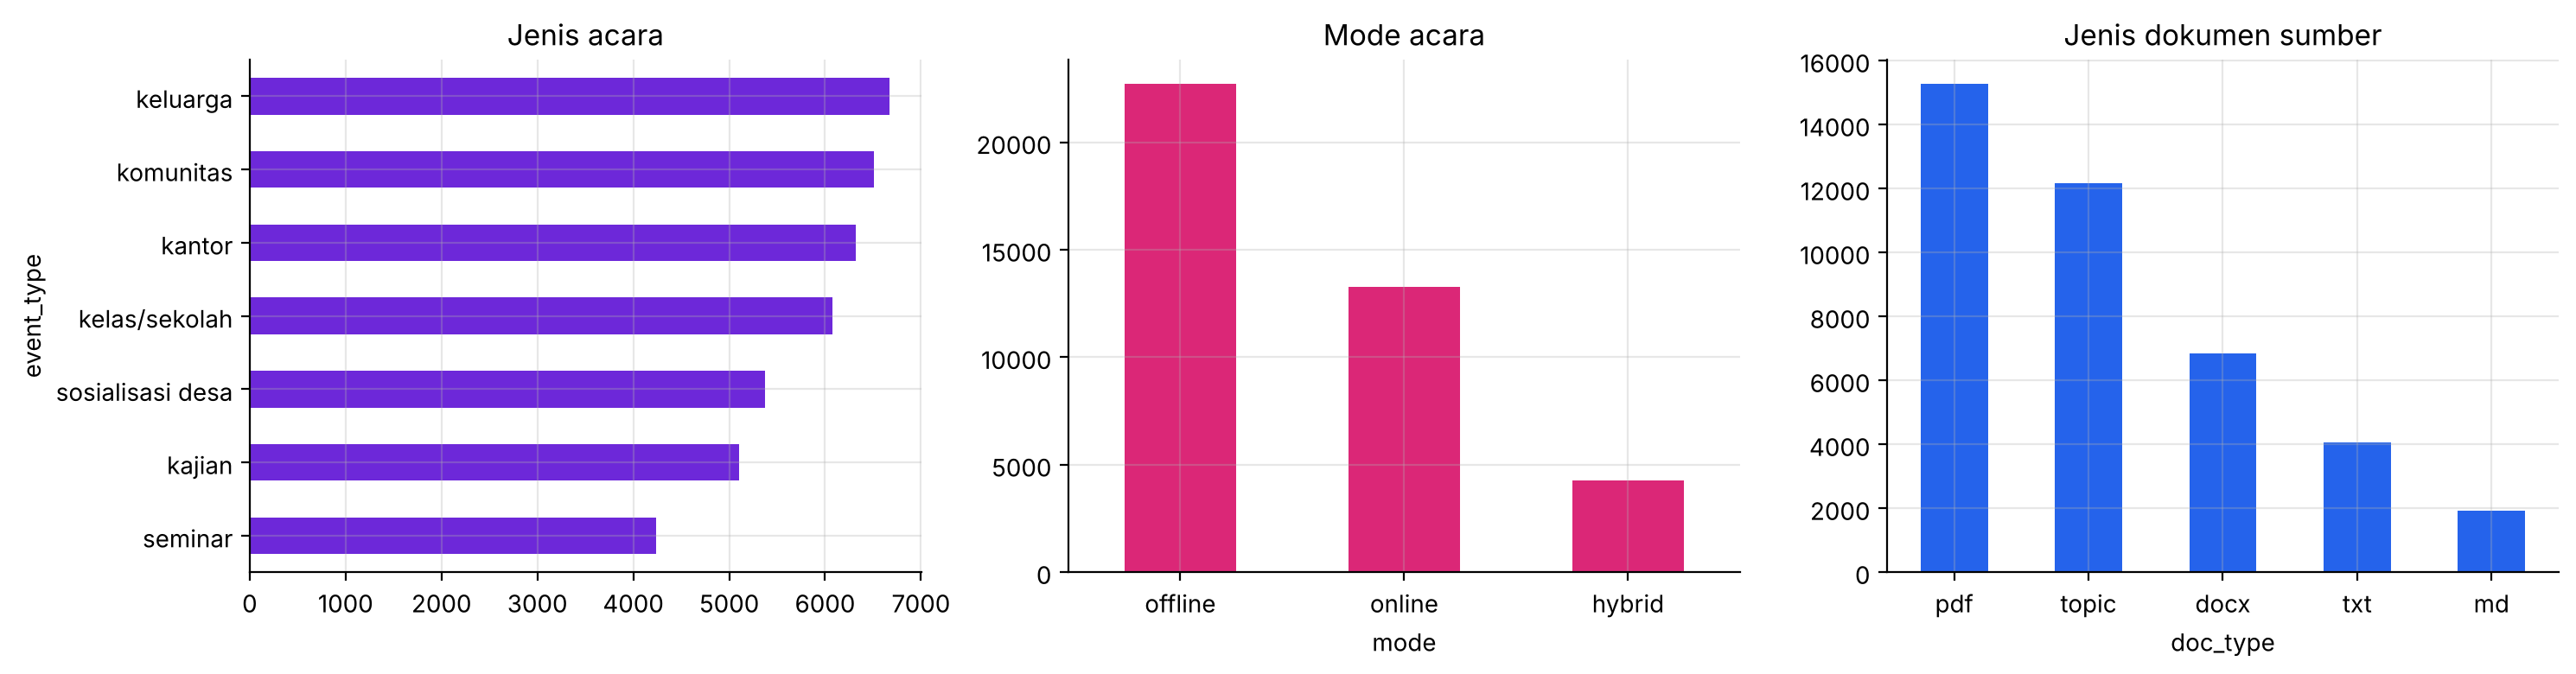

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
clean['event_type'].value_counts().sort_values().plot.barh(ax=axs[0], color='#6D28D9', title='Jenis acara')
clean['mode'].value_counts().plot.bar(ax=axs[1], color='#DB2777', title='Mode acara', rot=0)
clean['doc_type'].value_counts().plot.bar(ax=axs[2], color='#2563EB', title='Jenis dokumen sumber', rot=0)
plt.tight_layout(); plt.show()

**Insight dokumen:** PDF dan topik singkat mendominasi, disusul DOCX. Ini dasar keputusan mendukung PDF, DOCX, TXT/MD, dan topik ketik; OCR/gambar/video tidak didukung karena berat untuk free tier.

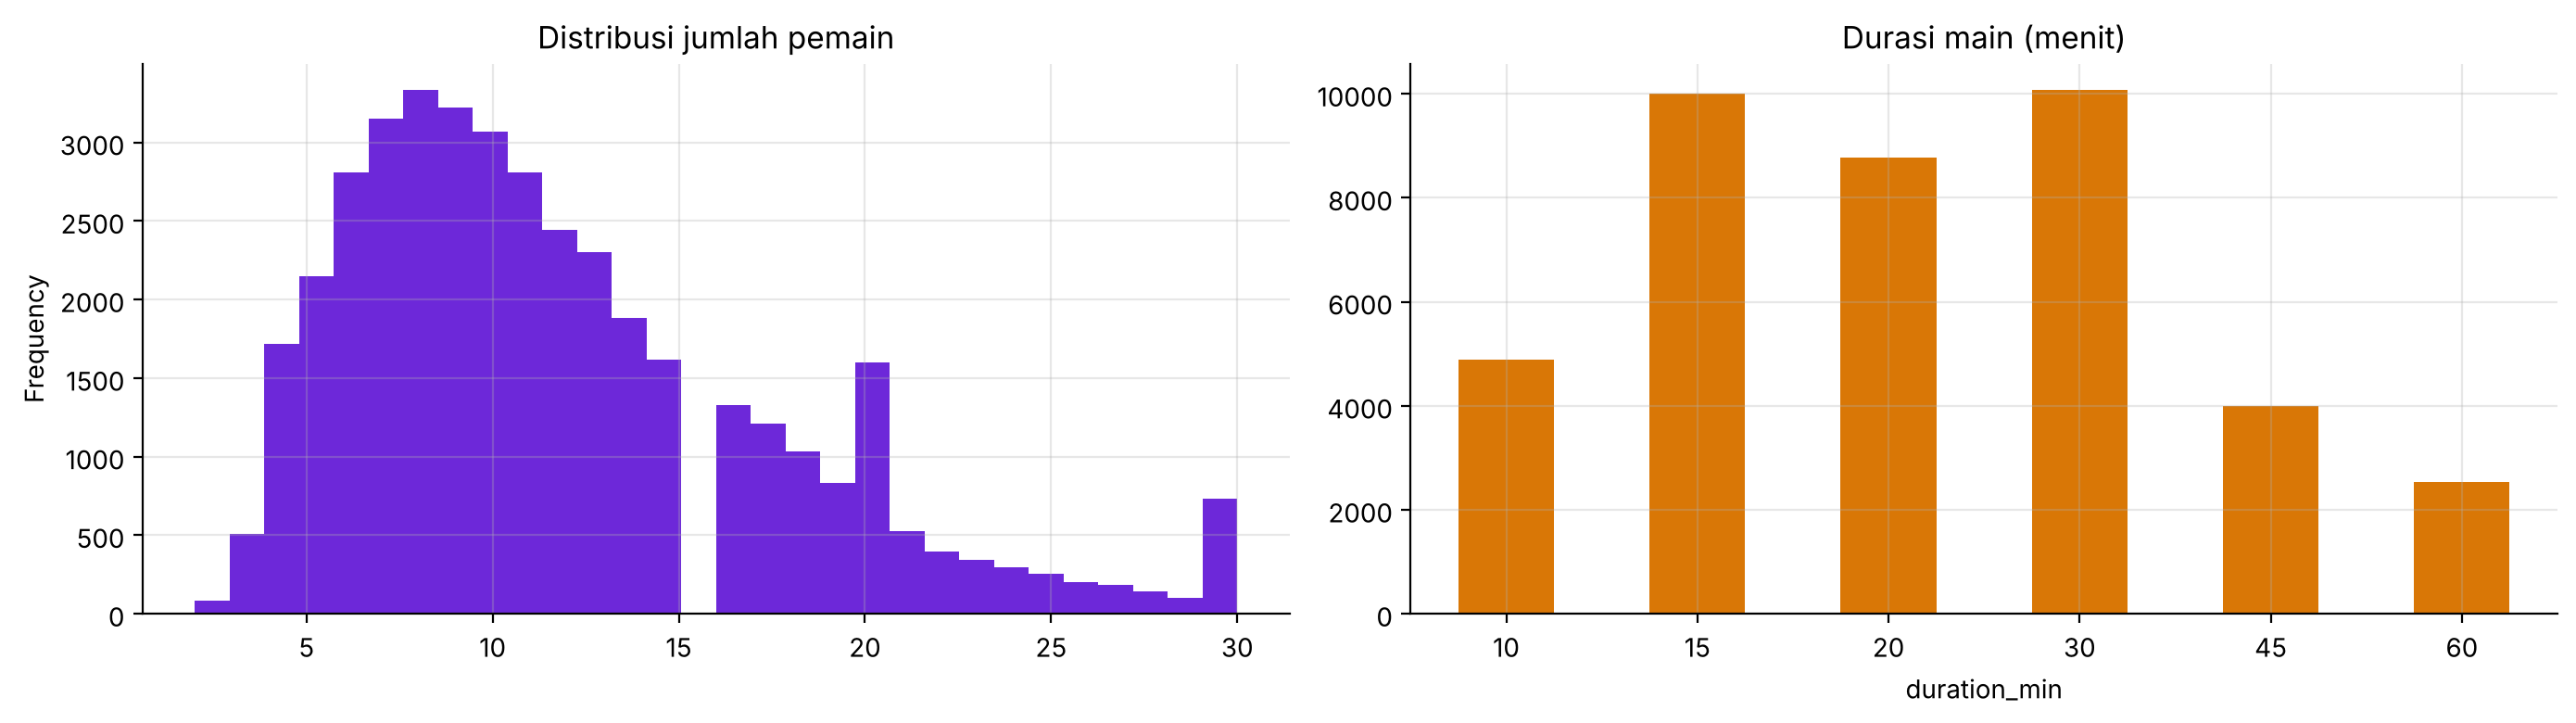

count    40275.0
mean        11.8
std          5.9
min          2.0
25%          7.0
50%         11.0
75%         15.0
max         30.0
Name: players, dtype: float64


In [10]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
clean['players'].plot.hist(bins=30, ax=axs[0], color='#6D28D9', title='Distribusi jumlah pemain')
clean['duration_min'].value_counts().sort_index().plot.bar(ax=axs[1], color='#D97706', rot=0, title='Durasi main (menit)')
plt.tight_layout(); plt.show()
print(clean['players'].describe().round(1))

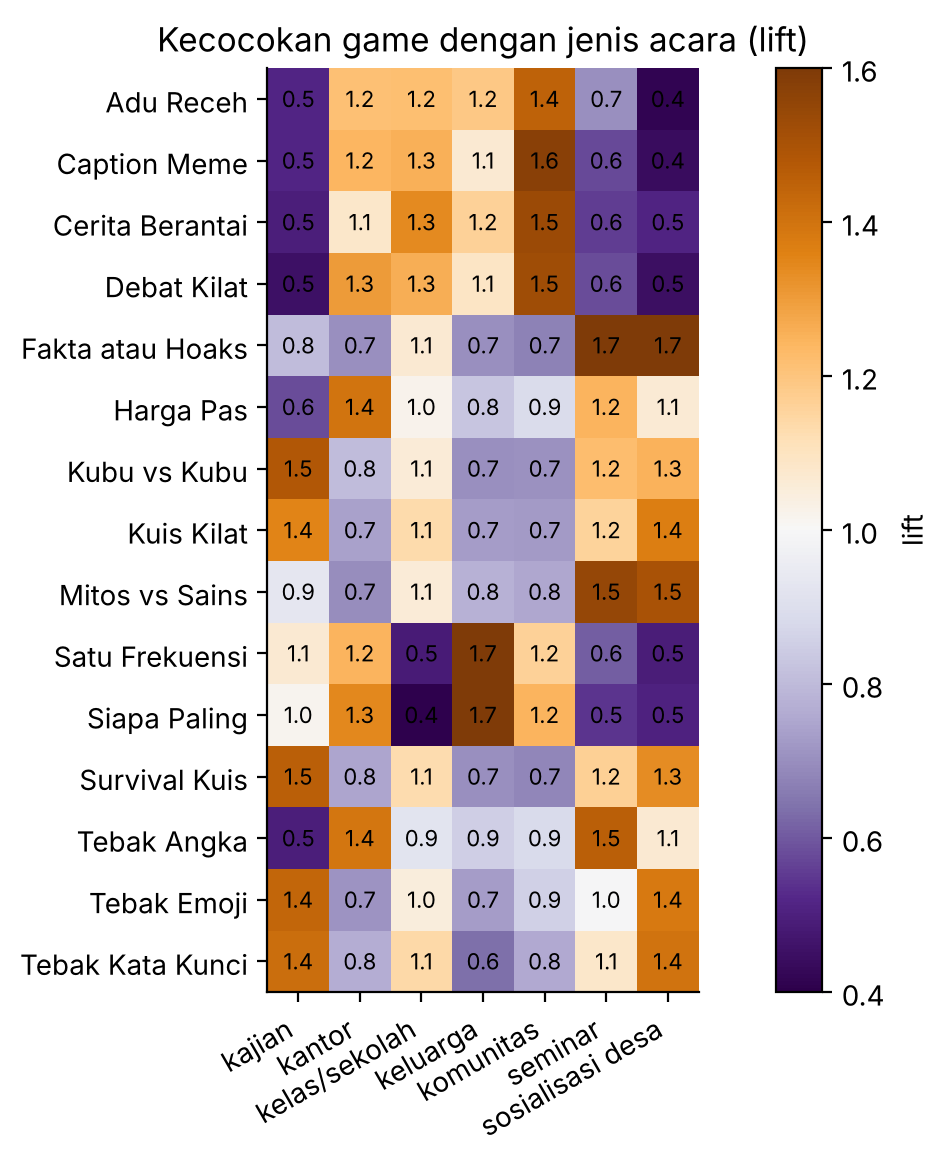

In [11]:
# afinitas game x jenis acara (lift = P(acara|game) / P(acara))
ct = pd.crosstab(clean['game_id'].map(NAMES), clean['event_type'], normalize='index')
lift = ct / clean['event_type'].value_counts(normalize=True)
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(lift.values, cmap='PuOr_r', vmin=0.4, vmax=1.6)
ax.set_xticks(range(len(lift.columns)), lift.columns, rotation=30, ha='right'); ax.set_yticks(range(len(lift)), lift.index)
for i in range(lift.shape[0]):
    for j in range(lift.shape[1]):
        ax.text(j, i, f'{lift.values[i, j]:.1f}', ha='center', va='center', fontsize=8)
ax.grid(False); plt.colorbar(im, label='lift'); ax.set_title('Kecocokan game dengan jenis acara (lift)'); plt.show()

**Insight:** game kuis cocok untuk kajian/kelas/sosialisasi, game opini & voting (Satu Frekuensi, Caption Meme) lebih cocok untuk keluarga, kantor, dan komunitas. Lift ini dipakai langsung oleh fitur rekomendasi di aplikasi.

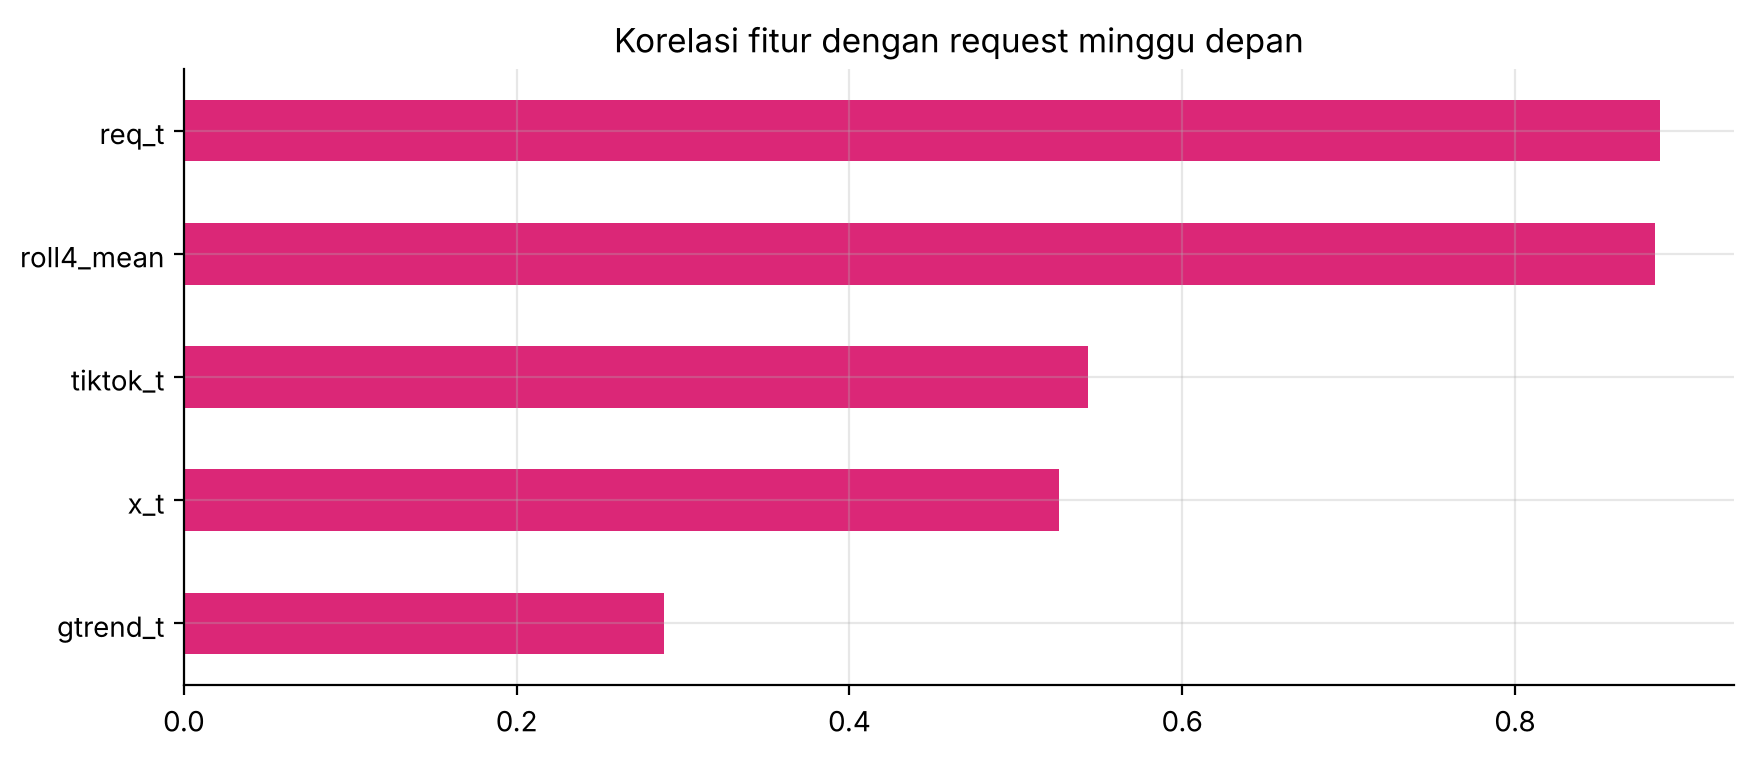

gtrend_t      0.289
tiktok_t      0.543
x_t           0.526
req_t         0.887
roll4_mean    0.884
Name: req_next, dtype: float64

In [12]:
# apakah sinyal tren minggu ini memprediksi request minggu depan?
panel = build_panel(clean, sig)
act = panel[panel['active']].dropna(subset=[TARGET])
corr = act[['gtrend_t','tiktok_t','x_t','req_t','roll4_mean', TARGET]].corr()[TARGET].drop(TARGET)
corr.sort_values().plot.barh(color='#DB2777', title='Korelasi fitur dengan request minggu depan'); plt.show()
corr.round(3)

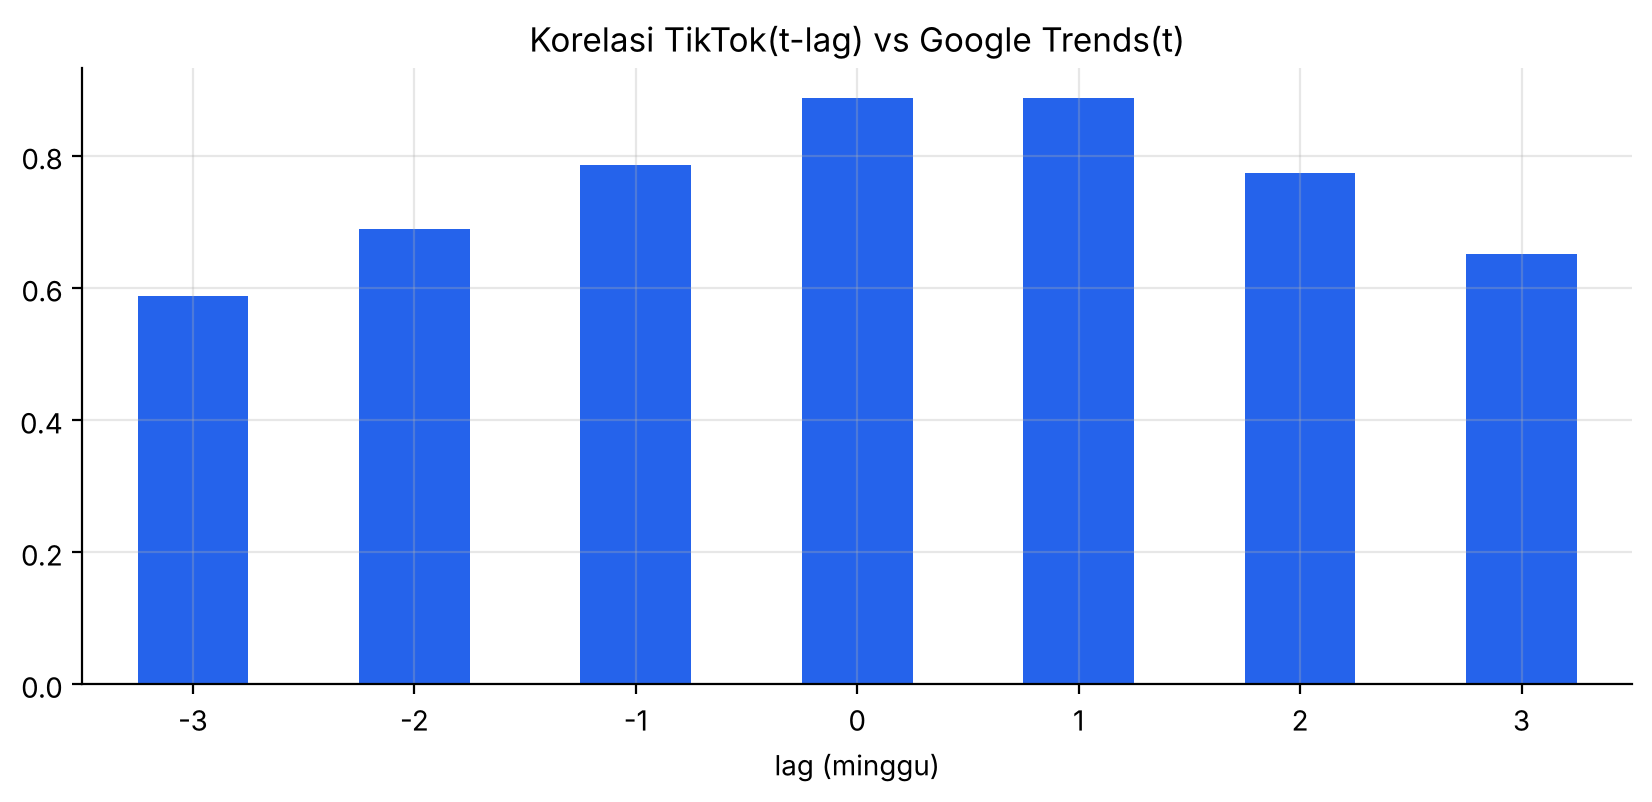

In [13]:
# lead-lag: TikTok mendahului Google Trends?
res = {}
for lag in range(-3, 4):
    vals = []
    for gid, d in sig.groupby('game_id'):
        vals.append(d['tiktok_mentions'].shift(lag).corr(d['google_trends']))
    res[lag] = np.nanmean(vals)
pd.Series(res).plot.bar(color='#2563EB', rot=0, title='Korelasi TikTok(t-lag) vs Google Trends(t)'); plt.xlabel('lag (minggu)'); plt.show()

**Insight:** korelasi tertinggi di lag +1, yaitu mention TikTok minggu lalu paling mirip dengan pencarian Google minggu ini. Karena itu fitur TikTok penting sebagai sinyal dini.

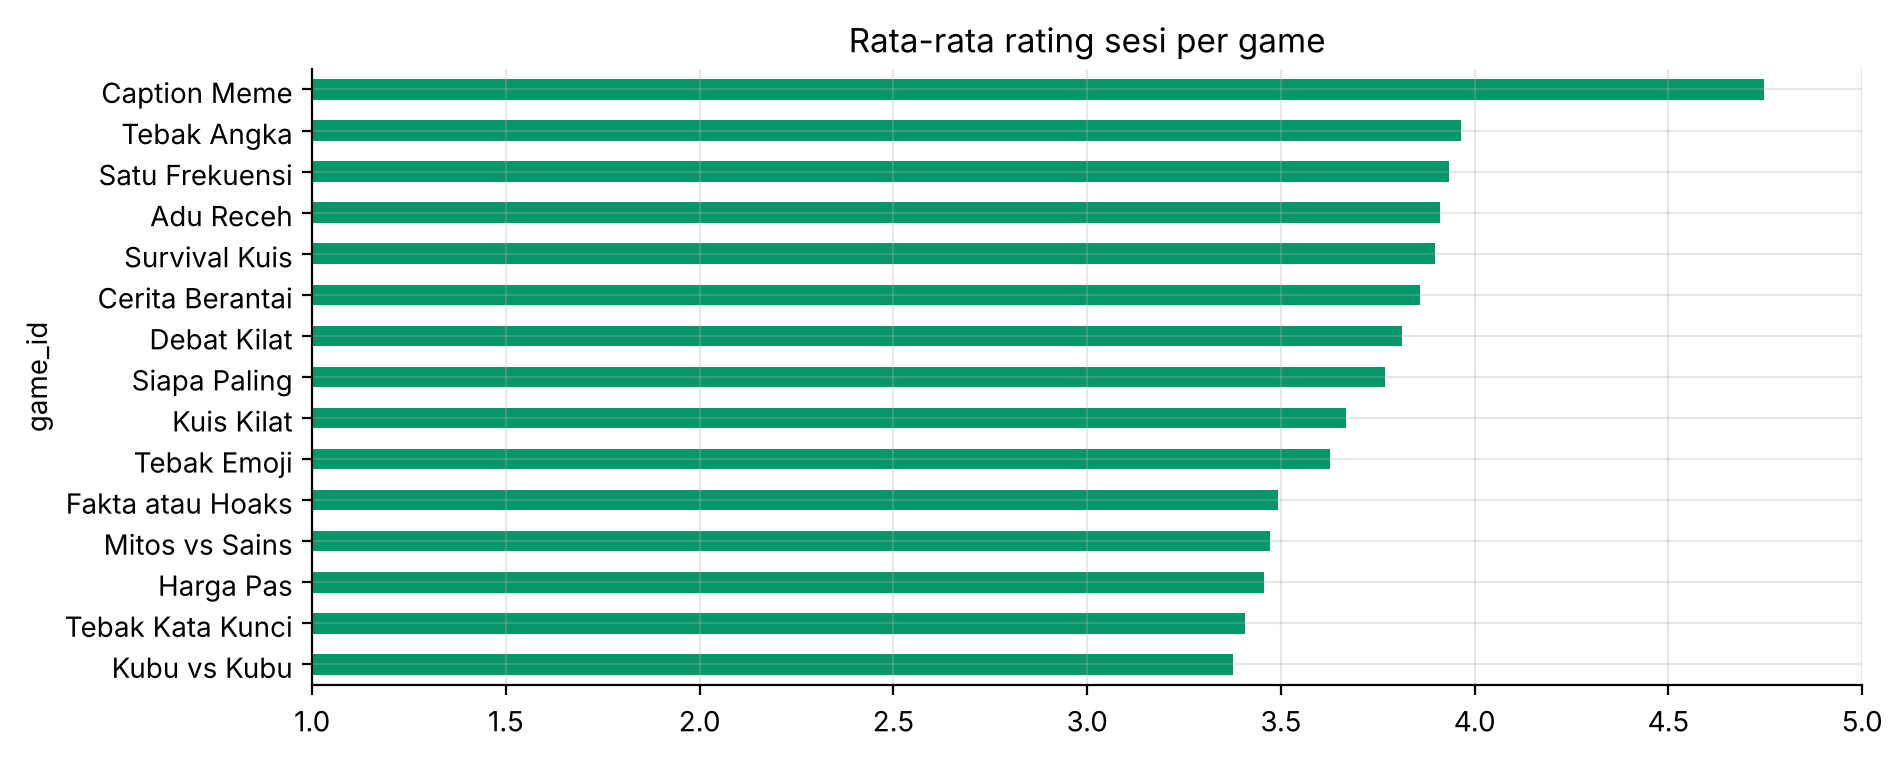

In [14]:
rating = clean.groupby(clean['game_id'].map(NAMES))['rating'].mean().sort_values()
rating.plot.barh(color='#059669', title='Rata-rata rating sesi per game', xlim=(1, 5)); plt.show()

## 4. Feature Engineering
Unit: (game, minggu). Target `req_next` = jumlah request minggu depan.
Fitur: lag request 1-3 minggu, rata-rata & std rolling 4 minggu, rasio pertumbuhan, Google Trends & delta,
TikTok & delta, X, umur game, penanda musim minggu depan (Ramadan, Agustus, akhir tahun, libur sekolah),
dan one-hot mekanik game.

In [15]:
print(len(FEATURES), 'fitur'); act[['game_id','week'] + FEATURES[:8] + [TARGET]].tail()

22 fitur


,game_id,week,req_t,req_lag1,req_lag2,req_lag3,roll4_mean,roll4_std,growth,gtrend_t,req_next
1554,voting_meme,2026-10-19,102,92.0,98.0,90.0,95.50,5.507571,1.067358,100.0,100.0
1555,voting_meme,2026-10-26,100,102.0,92.0,98.0,98.00,4.320494,1.020202,100.0,117.0
1556,voting_meme,2026-11-02,117,100.0,102.0,92.0,102.75,10.436315,1.137349,100.0,114.0
1557,voting_meme,2026-11-09,114,117.0,100.0,102.0,108.25,8.500000,1.052632,100.0,99.0
1558,voting_meme,2026-11-16,99,114.0,117.0,100.0,107.50,9.327379,0.921659,100.0,114.0


## 5. Modeling: eksperimen 5 model + baseline
Split berbasis waktu: 26 minggu terakhir sebagai test (tanpa shuffle, agar tidak ada kebocoran masa depan).
Metrik: MAE, RMSE, R², dan **Precision@10** (seberapa tepat Top-10 prediksi dibanding Top-10 aktual tiap minggu),
karena Top-10 itulah yang dipakai aplikasi.

In [16]:
from scripts.train_model import main as train
report = train()
res = pd.DataFrame(report['results']).set_index('model'); res

Ridge Regression                 MAE=6.105  P@10=0.896


Poisson GLM                      MAE=11.275  P@10=0.885


Random Forest                    MAE=6.406  P@10=0.904


Gradient Boosting (HistGB)       MAE=6.334  P@10=0.885


MLP (Neural Net)                 MAE=6.833  P@10=0.877


BEST: Ridge Regression


,MAE,RMSE,R2,Precision@10
model,,,,
Baseline (naive: = minggu ini),6.913,9.242,0.8264,0.8615
Ridge Regression,6.105,8.074,0.8675,0.8962
Poisson GLM,11.275,30.592,-0.9019,0.8846
Random Forest,6.406,9.074,0.8327,0.9038
Gradient Boosting (HistGB),6.334,8.735,0.8450,0.8846
MLP (Neural Net),6.833,9.272,0.8253,0.8769


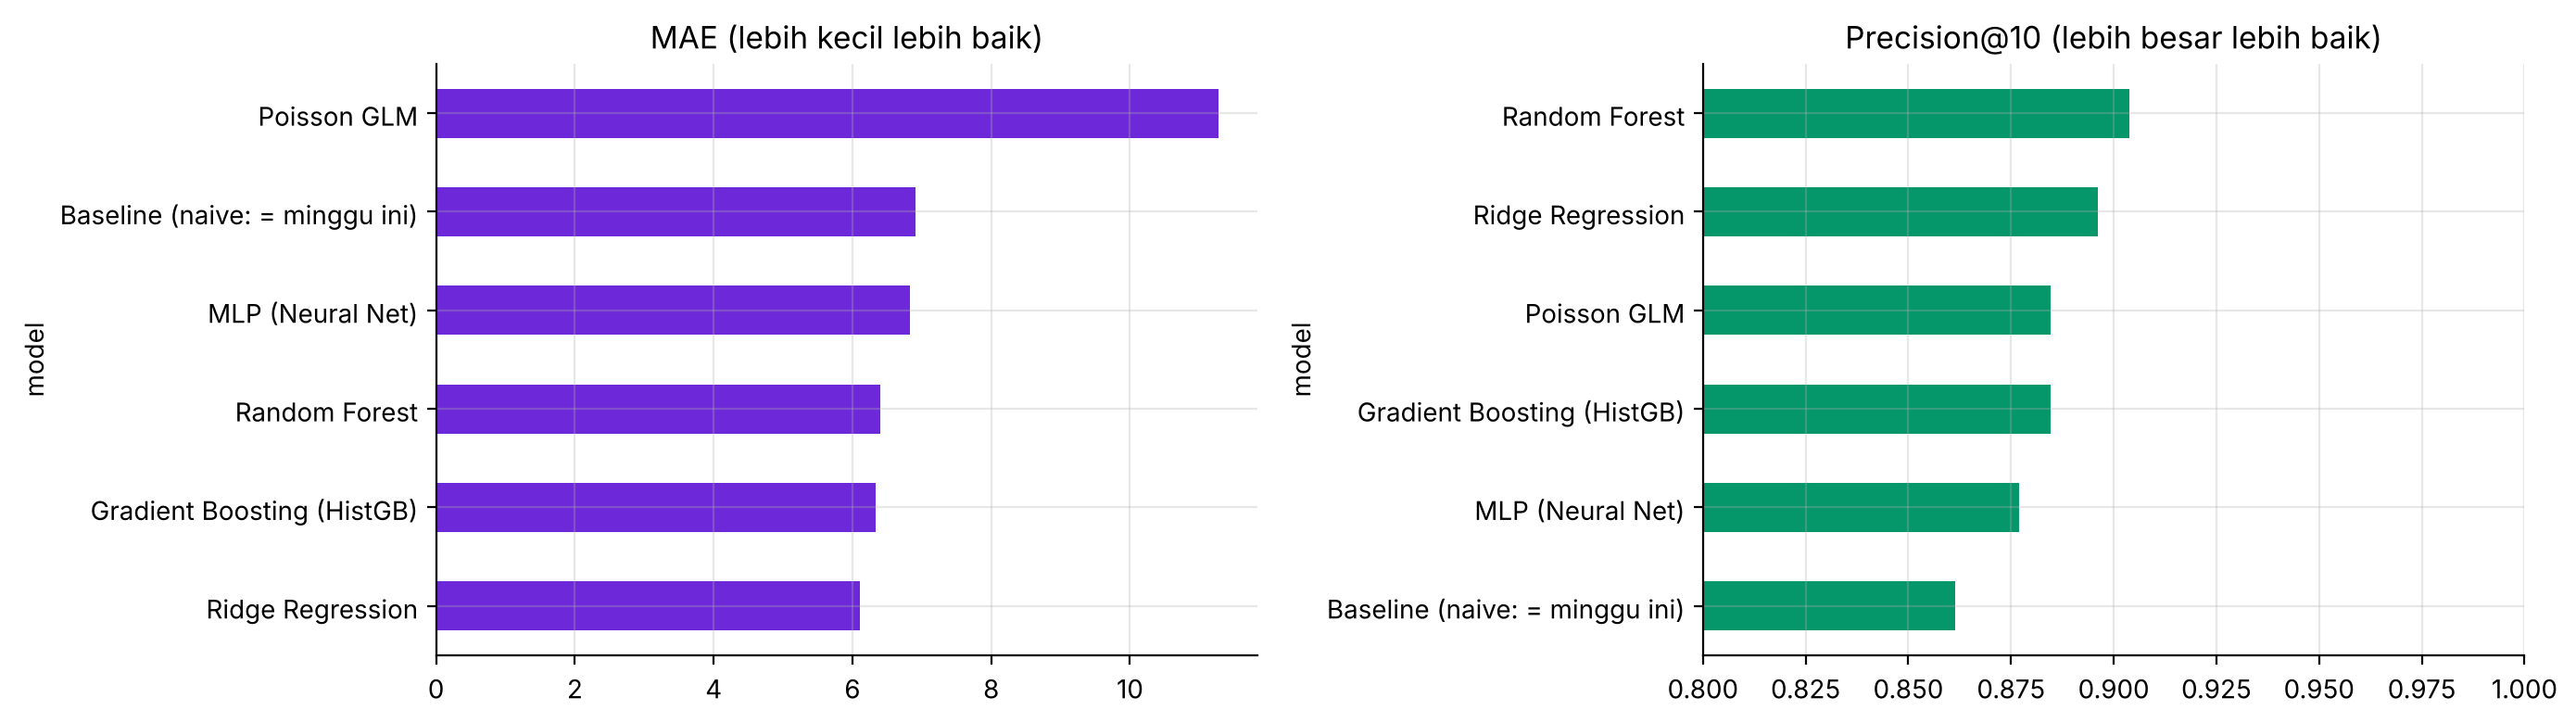

Model terbaik: Ridge Regression


In [17]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
res['MAE'].sort_values().plot.barh(ax=axs[0], color='#6D28D9', title='MAE (lebih kecil lebih baik)')
res['Precision@10'].sort_values().plot.barh(ax=axs[1], color='#059669', title='Precision@10 (lebih besar lebih baik)', xlim=(.8, 1))
plt.tight_layout(); plt.show()
print('Model terbaik:', report['best_model'])

**Pemilihan model.** Model dipilih berdasarkan MAE terkecil di data test. Semua model mengalahkan baseline naive
(MAE dan Precision@10). Model linear (Ridge) unggul karena hubungan fitur-target memang dominan linear
(lag + sinyal tren), lebih stabil, dan sangat ringan untuk dijalankan di Streamlit Cloud gratis.

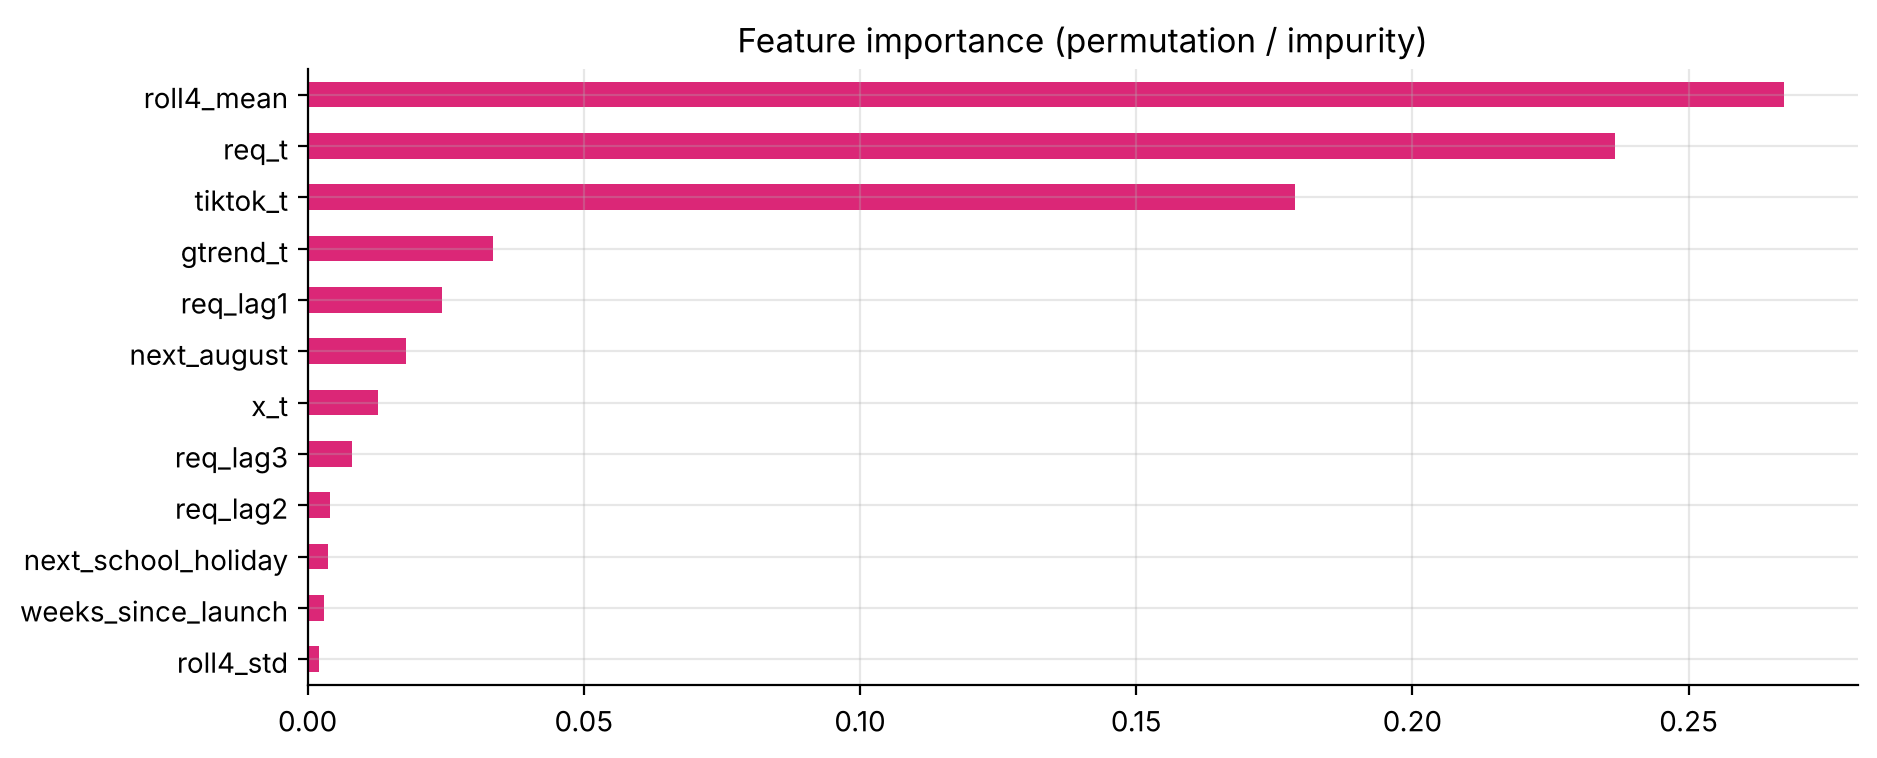

In [18]:
fi = pd.Series(report['feature_importance']).head(12).sort_values()
fi.plot.barh(color='#DB2777', title='Feature importance (permutation / impurity)'); plt.show()

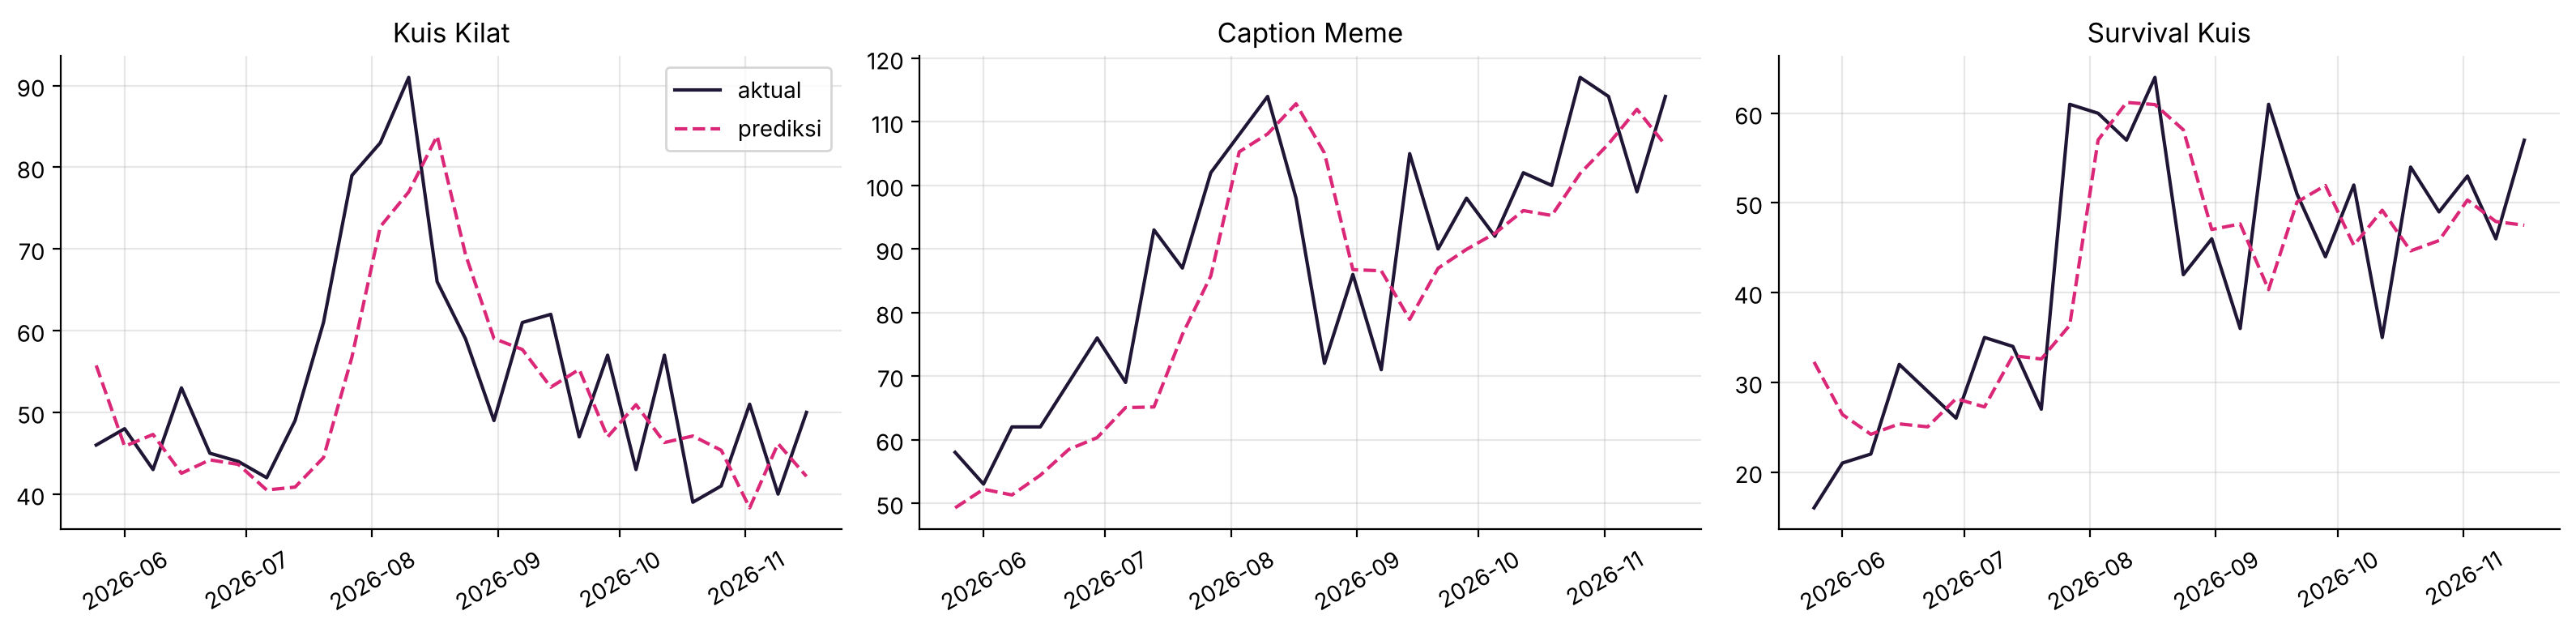

In [19]:
import joblib
from core.config import MODEL_PATH
bundle = joblib.load(ROOT / MODEL_PATH.relative_to(ROOT))
weeks = sorted(act['week'].unique()); cut = weeks[-26]
test = act[act['week'] >= cut].copy(); test['pred'] = bundle['model'].predict(test[FEATURES])
fig, axs = plt.subplots(1, 3, figsize=(16, 4), sharey=False)
for ax, gid in zip(axs, ['kuis_kilat', 'voting_meme', 'survival_kuis']):
    d = test[test['game_id'] == gid]
    ax.plot(d['week'], d[TARGET], label='aktual', color='#1F1534'); ax.plot(d['week'], d['pred'], label='prediksi', color='#DB2777', ls='--')
    ax.set_title(NAMES[gid]); ax.tick_params(axis='x', rotation=30)
axs[0].legend(); plt.tight_layout(); plt.show()

## 6. Library Top-10, slot multiverse, dan validasi ground truth
Setiap update, ground truth menghitung Top-10 baru lalu membandingkan dengan versi sebelumnya:
overlap (berapa game yang masih sama), Kendall tau (apakah urutannya stabil), dan game yang masuk/keluar.
**STABIL** jika overlap >= 8/10, selain itu **BERUBAH**. Di bawah ini simulasi mingguan selama periode test.

{'STABIL': 25, 'BASELINE': 1} | rata-rata P@10 vs aktual: 0.912


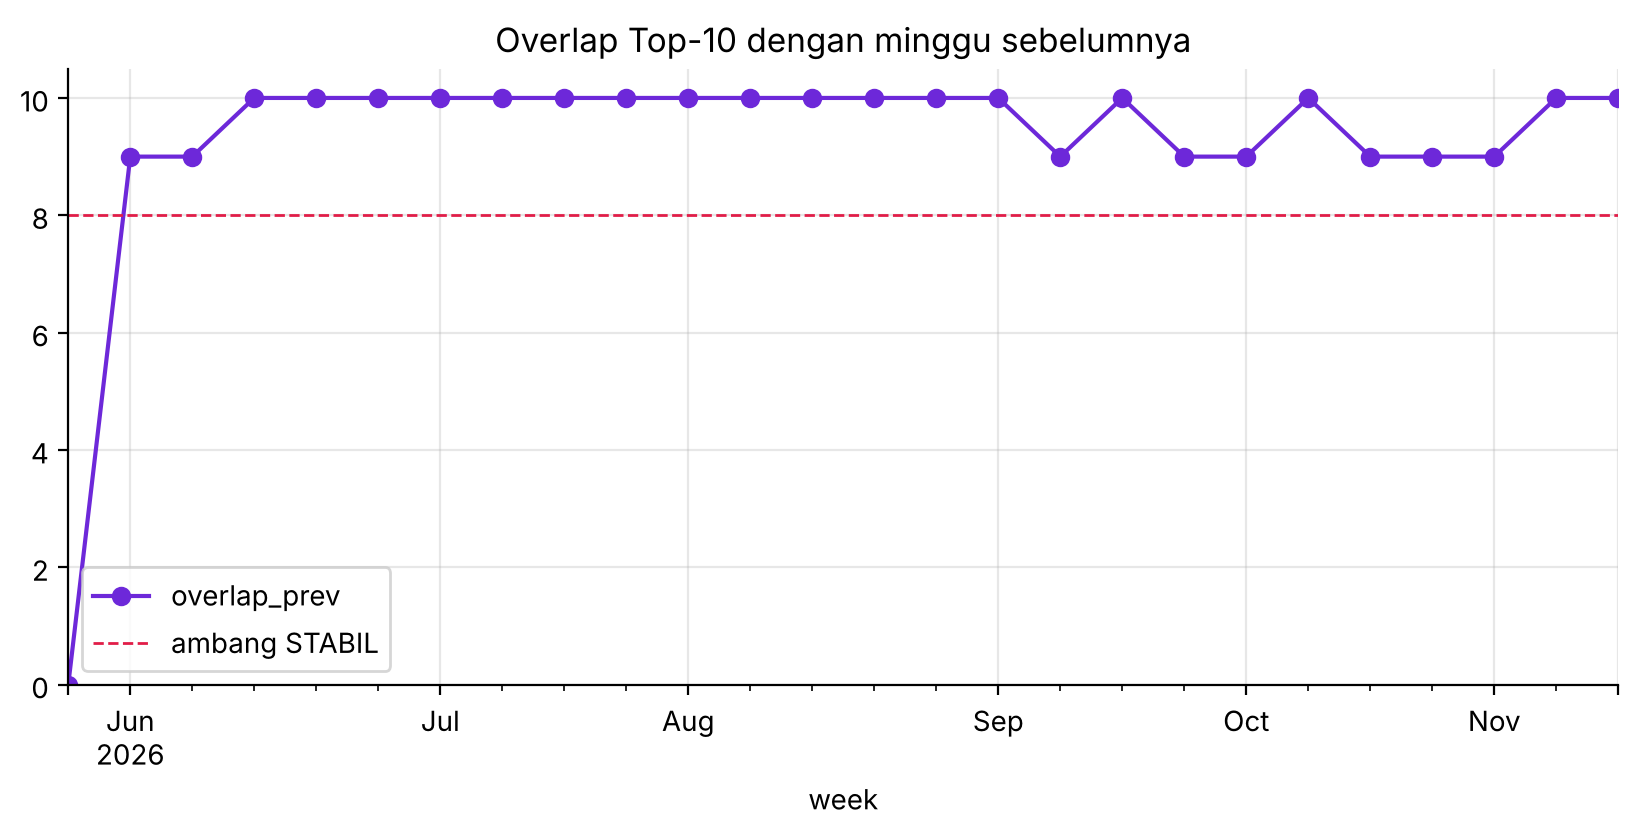

,week,overlap_prev,verdict,p10_vs_aktual,masuk
18,2026-09-28,9,STABIL,0.8,tebak_angka
19,2026-10-05,9,STABIL,0.8,tim_vs_tim
20,2026-10-12,10,STABIL,0.9,
21,2026-10-19,9,STABIL,0.9,tebak_angka
22,2026-10-26,9,STABIL,0.8,tim_vs_tim
23,2026-11-02,9,STABIL,1.0,tebak_kata_kunci
24,2026-11-09,10,STABIL,0.9,
25,2026-11-16,10,STABIL,1.0,


In [20]:
from core.ground_truth import compare
snaps, prev = [], []
for w in sorted(test['week'].unique()):
    d = test[test['week'] == w]
    top_pred = list(d.nlargest(10, 'pred')['game_id']); top_act = set(d.nlargest(10, TARGET)['game_id'])
    c = compare(prev, top_pred)
    snaps.append({'week': w, 'overlap_prev': c['overlap'], 'verdict': c['verdict'],
                  'p10_vs_aktual': len(set(top_pred) & top_act) / 10, 'masuk': ','.join(c['masuk']) if prev else ''})
    prev = top_pred
gt = pd.DataFrame(snaps)
print(gt['verdict'].value_counts().to_dict(), '| rata-rata P@10 vs aktual:', gt['p10_vs_aktual'].mean().round(3))
ax = gt.set_index('week')[['overlap_prev']].plot(marker='o', color='#6D28D9', ylim=(0, 10.5), title='Overlap Top-10 dengan minggu sebelumnya')
ax.axhline(8, color='#E11D48', ls='--', lw=1, label='ambang STABIL'); ax.legend(); plt.show()
gt.tail(8)

**Aturan slot multiverse.** Game baru (custom/AI) masuk 1 slot eksperimen. Dipromosikan ke Top-10 jika prediksi
permintaannya >= game peringkat 10 dan sudah >= 5 request. Dihapus jika setelah 7 hari request < 5.
Simulasi di bawah memakai modul aplikasi yang sama (`core/library.py`) dengan state sementara.

In [21]:
import tempfile, core.library as L, core.features as F
from datetime import datetime, timedelta, timezone
from core.rules import TEMPLATE, validate
tmp = Path(tempfile.mkdtemp())
L.RUNTIME_DIR, L.LIBRARY_STATE, L.RUNTIME_REQUESTS = tmp, tmp/'state.json', tmp/'req.csv'
F.RUNTIME_REQUESTS = tmp/'req.csv'; L._pred_cache.clear()
L.refresh_library()
spec = validate({**TEMPLATE, 'name': 'Tebak Ayat'})[2]
gid, status = L.add_custom_game(spec); print('daftar:', status)
for _ in range(60): L.log_request(gid, {'players': 12})
st = L.refresh_library(); print('setelah 60 request -> masuk Top-10?', gid in st['top'])
gid2, _ = L.add_custom_game(validate({**TEMPLATE, 'name': 'Game Sepi'})[2])
s = L.load_state(); s['multiverse']['created_at'] = (datetime.now(timezone.utc) - timedelta(days=8)).isoformat(); L.save_state(s)
st = L.refresh_library(); print('game sepi setelah 8 hari ->', st['custom_games'][gid2]['status'])
for e in st['events'][-4:]: print(' -', e['msg'])

daftar: multiverse
setelah 60 request -> masuk Top-10? True


game sepi setelah 8 hari -> evicted
 - Top-10: 'tebak_kata_kunci' keluar.
 - Top-10: 'c_a260a522' masuk.
 - MULTIVERSE: 'Game Sepi' masuk slot eksperimen.
 - HAPUS: 'Game Sepi' dikeluarkan dari multiverse (sepi peminat).


## 7. Generative AI: agent + generator konten
- **Agent** (`core/agent.py`): LLM Gemini (free tier) dengan function calling, cadangan OpenAI, dan planner
  offline. Punya 6 tools: `get_trends`, `recommend_games`, `read_document`, `validate_custom_game`,
  `register_custom_game`, `create_room`.
- **Generator** (`core/generator.py`): retrieval TF-IDF memilih potongan dokumen yang relevan, LLM membuat
  konten JSON sesuai mekanik, divalidasi skemanya, dan di-cache (TTL 30 menit). Tanpa LLM, generator ekstraktif
  (cloze, fakta/hoaks dengan substitusi kata kunci, angka dari teks) tetap menghasilkan game.
- **Aturan kunci** (`core/rules.py`): 4-7 aturan, wajib peran host & peserta, batas pemain/ronde/durasi.

In [22]:
from core.documents import parse_bytes, keywords
from core.generator import generate_rounds
doc = parse_bytes('materi_pemilahan_sampah.md', (ROOT/'samples/materi_pemilahan_sampah.md').read_bytes())
print('kata kunci:', keywords(doc, 10))
for gid in ['kuis_kilat', 'fakta_hoaks', 'tebak_angka']:
    rounds, meta = generate_rounds(doc, GAME_BY_ID[gid], 2, 'sampah', use_llm=False)
    print(f"\n[{NAMES[gid]}] sumber={meta['provider']}")
    for r in rounds: print('  ', json.dumps(r, ensure_ascii=False)[:180])

kata kunci: ['solusi', 'pengelolaan', 'desa', 'prinsip', 'tanah', 'minggu', 'kompos', 'diolah', 'materi', 'pilah']

[Kuis Kilat] sumber=offline
   {"q": "Lengkapi: Bank sampah adalah tempat ____ menabung sampah anorganik yang sudah dipilah.", "options": ["materi", "warga", "botol", "kuning"], "answer": 1}
   {"q": "Lengkapi: Jadwal pengangkutan sampah ____ dilakukan 2 kali seminggu.", "options": ["desa", "kaleng", "sosialisasi", "tahun"], "answer": 0}

[Fakta atau Hoaks] sumber=offline
   {"q": "Sampah ditimbang, dicatat, lalu dihargai dengan uang sesuai jenisnya.", "answer": true, "explain": "Sesuai materi."}
   {"q": "Karena itu, memilah sampah organik di rumah sangat mengurangi hijau TPA.", "answer": false, "explain": "Seharusnya 'beban', bukan 'hijau'."}

[Tebak Angka] sumber=offline
   {"q": "Botol plastik membutuhkan waktu sekitar **berapa?** tahun untuk terurai di alam.", "answer": 450.0, "unit": ""}
   {"q": "Di Indonesia, sekitar **berapa?** sampah rumah tangga adalah sisa mak

In [23]:
ok, errs, _ = validate({**TEMPLATE, 'rules': ['cuma satu aturan'], 'roles': {'host': 'bacakan soal'}, 'max_players': 80})
print('valid:', ok); [print(' -', e) for e in errs]

valid: False
 - Jumlah aturan harus 4-7 (sekarang 1).
 - Peran 'peserta' wajib didefinisikan.
 - Maks pemain harus 2-30 (sekarang 80).


[None, None, None]

In [24]:
from core.agent import AgentContext, chat
ctx = AgentContext(base_url='https://ai-game-generator.streamlit.app', doc=doc, use_llm=False)
answer, trace, engine = chat(ctx, [{'role': 'user', 'content': 'Sosialisasi desa 20 warga di Bandung, offline 30 menit, materi pilah sampah'}])
print('mesin:', engine); print('tools :', [t['tool'] for t in trace]); print(); print(answer)

mesin: offline planner (LLM dimatikan)
tools : ['recommend_games', 'read_document', 'create_room']

Asumsi acara: **20 orang, 30 menit, sosialisasi desa, offline**, Jawa Barat.

Rekomendasi: **Fakta atau Hoaks** (sering dipakai di acara sosialisasi desa). Alternatif: Kuis Kilat, Survival Kuis.

Room **BUGEQ** siap, 15 ronde.

- Link HOST (buka di laptop/HP kamu): https://ai-game-generator.streamlit.app/?room=BUGEQ&role=host&key=r6-H9m1pi6Y
- Link PESERTA (bagikan ke teman): https://ai-game-generator.streamlit.app/?room=BUGEQ


## 8. Kesimpulan
1. Sinyal tren (terutama TikTok sebagai sinyal dini) + histori permintaan cukup untuk memprediksi game yang
   diminati minggu depan; model terbaik mengalahkan baseline naive dan menjaga Precision@10 di kisaran ~0,9.
2. Library dibatasi Top-10 + 1 slot multiverse, sehingga katalog tetap ringkas, relevan, dan game baru punya
   jalur adil untuk masuk atau dibuang otomatis.
3. Agent GenAI mengubah permintaan bahasa sehari-hari menjadi room siap main (link host + peserta), dengan konten
   dari dokumen acara, dibatasi aturan kunci dan batas komputasi agar aman di layanan gratis.
4. Ground truth tunggal membuat keputusan library dapat diaudit: setiap update tercatat apakah Top-10 STABIL atau BERUBAH.

**Saran:** ganti data sintetis dengan Google Trends asli (`scripts/fetch_trends.py`) dan log aplikasi nyata,
tambah evaluasi kualitas soal oleh manusia (rating per ronde), dan pindahkan state room ke database (mis.
Firebase/Supabase) bila pemain > 30 atau butuh banyak instance.